In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from mplsoccer import VerticalPitch

tirs = pd.read_csv("../data/messi_tirs_2011_12.csv")
print(tirs.shape)
tirs.head()

(198, 10)


,match_date,adversaire,domicile,minute,x,y,shot_statsbomb_xg,shot_outcome,shot_body_part,shot_type
0,2011-09-17,Osasuna,True,4,116.9,38.4,0.689756,Goal,Left Foot,Open Play
1,2011-09-17,Osasuna,True,7,103.9,35.1,0.099668,Saved,Left Foot,Open Play
2,2011-09-17,Osasuna,True,29,111.0,38.9,0.218658,Post,Head,Open Play
3,2011-09-17,Osasuna,True,40,108.7,38.6,0.273771,Goal,Left Foot,Open Play
4,2011-09-17,Osasuna,True,50,108.3,51.6,0.104451,Post,Left Foot,Open Play


### let's build the field without informations to visualize it shape

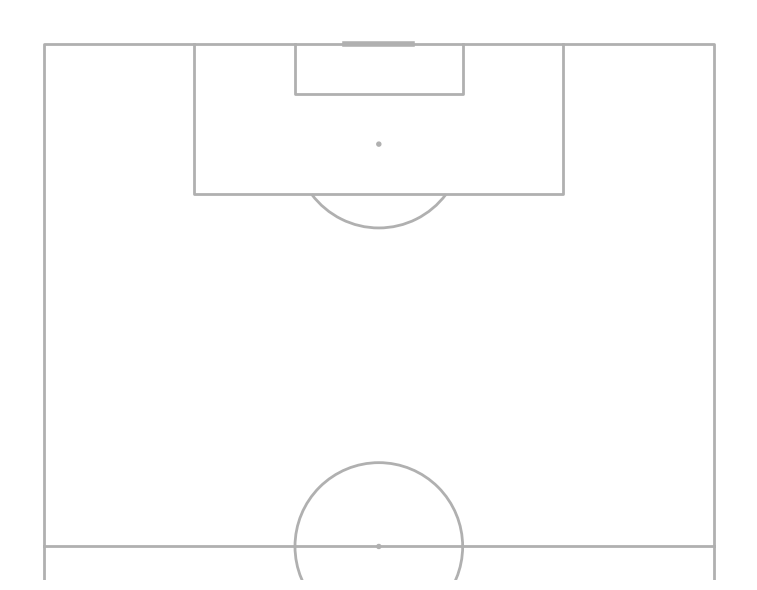

In [2]:
pitch = VerticalPitch(pitch_type="statsbomb", half=True)
fig, ax = pitch.draw(figsize=(8, 6))
plt.show()

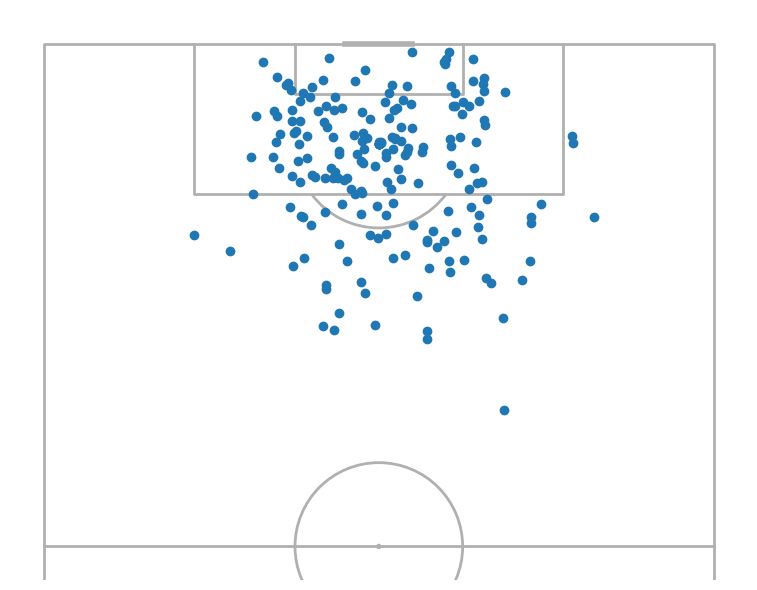

In [3]:
pitch = VerticalPitch(pitch_type="statsbomb", half=True)
fig, ax = pitch.draw(figsize=(8, 6))

pitch.scatter(tirs["x"], tirs["y"], ax=ax)

plt.show()

### on this plot, we point out all the shots by Messi, not only the goals but every shots that he made. Let's distinguish goals and missed shots. 

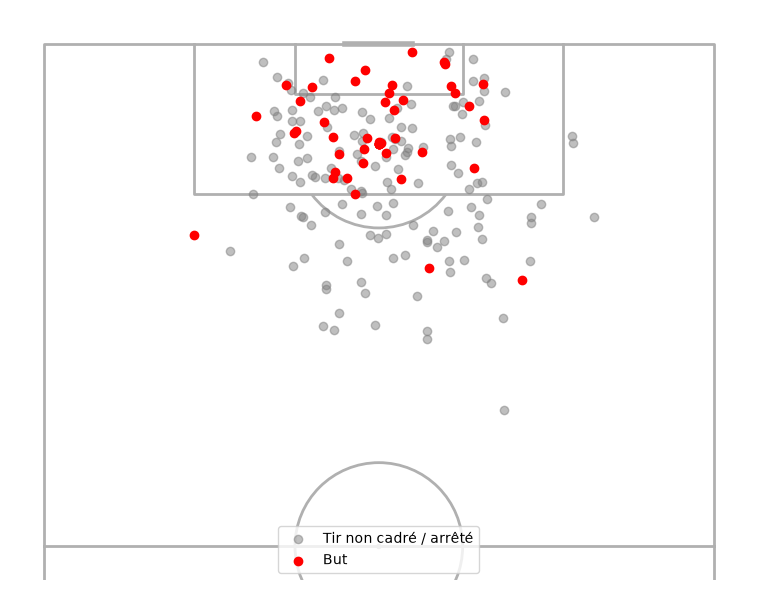

In [4]:
buts = tirs[tirs["shot_outcome"] == "Goal"]
rates = tirs[tirs["shot_outcome"] != "Goal"]

pitch = VerticalPitch(pitch_type="statsbomb", half=True)
fig, ax = pitch.draw(figsize=(8, 6))

pitch.scatter(rates["x"], rates["y"], ax=ax,
              color="grey", alpha=0.5, label="Tir non cadré / arrêté")
pitch.scatter(buts["x"], buts["y"], ax=ax,
              color="red", label="But")

ax.legend(loc="lower center")
plt.show()

### There we have a good shotmap, comprehensible for the basis of an analysis. Now let's make a shotmap more readable, more beautiful with a deeper analysis. 

In [5]:
nb_tirs = len(tirs)
nb_buts = (tirs["shot_outcome"] == "Goal").sum()
xg_total = tirs["shot_statsbomb_xg"].sum()
ecart = nb_buts - xg_total

buts = tirs[tirs["shot_outcome"] == "Goal"]
rates = tirs[tirs["shot_outcome"] != "Goal"]

def taille(xg):
    return xg * 900 + 30

print(nb_tirs, nb_buts, round(xg_total, 1), round(ecart, 1))

198 50 35.7 14.3


### This result give the number of shots (198), goals (50), xg_total (35.7) and ecart btw number of goals and what was expected (xg_goals) (14.3). Let's visualize that now !

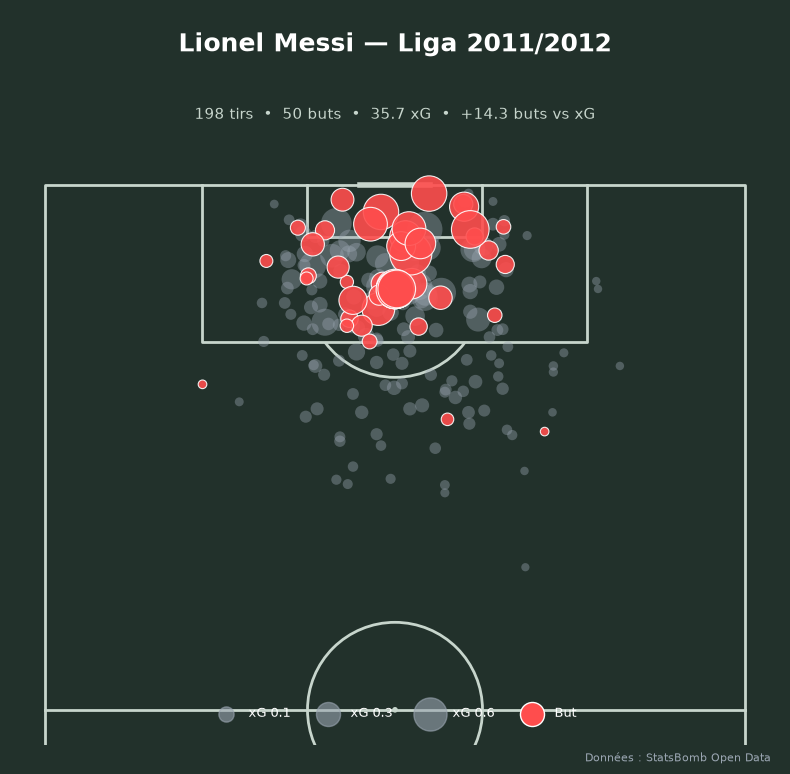

In [6]:
# --- Couleurs (on les définit une fois, en haut) ---
FOND   = "#22312b"
LIGNES = "#c7d5cc"
ROUGE  = "#ff4d4d"
GRIS   = "#9aa5b1"

# --- Le terrain ---
pitch = VerticalPitch(pitch_type="statsbomb", half=True,
                      pitch_color=FOND, line_color=LIGNES, pad_top=20)
fig, ax = pitch.draw(figsize=(8, 8))
fig.set_facecolor(FOND)

# --- Les tirs ---
pitch.scatter(rates["x"], rates["y"], s=taille(rates["shot_statsbomb_xg"]),
              color=GRIS, alpha=0.4, edgecolors="none", ax=ax, zorder=2)
pitch.scatter(buts["x"], buts["y"], s=taille(buts["shot_statsbomb_xg"]),
              color=ROUGE, edgecolors="white", linewidth=0.8, alpha=0.9, ax=ax, zorder=3)

# --- Titre et stats ---
pitch.text(136, 40, "Lionel Messi — Liga 2011/2012", ax=ax,
           ha="center", va="center", fontsize=18, fontweight="bold", color="white")
pitch.text(128, 40,
           f"{nb_tirs} tirs  •  {nb_buts} buts  •  {xg_total:.1f} xG  •  {ecart:+.1f} buts vs xG",
           ax=ax, ha="center", va="center", fontsize=11, color=LIGNES)

# --- Légende ---
for xg in [0.1, 0.3, 0.6]:
    ax.scatter([], [], s=taille(xg), color=GRIS, alpha=0.6, label=f"xG {xg}")
ax.scatter([], [], s=taille(0.3), color=ROUGE, edgecolors="white", label="But")
ax.legend(loc="lower center", ncol=4, frameon=False,
          labelcolor="white", fontsize=9, borderpad=1.5)

# --- Source ---
fig.text(0.97, 0.02, "Données : StatsBomb Open Data", ha="right", fontsize=8, color=GRIS)

# --- Sauvegarde puis affichage ---
fig.savefig("../figures/messi_shotmap_2011_12.png", dpi=300,
            bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()

### Let's observe this but without the penalty shots to better understand the real performance. 

In [7]:
sans_pen = tirs[tirs["shot_type"] != "Penalty"]
print("Buts hors penaltys :", (sans_pen["shot_outcome"] == "Goal").sum())
print("npxG               :", round(sans_pen["shot_statsbomb_xg"].sum(), 1))

Buts hors penaltys : 40
npxG               : 27.0


### Better visualisation there : 

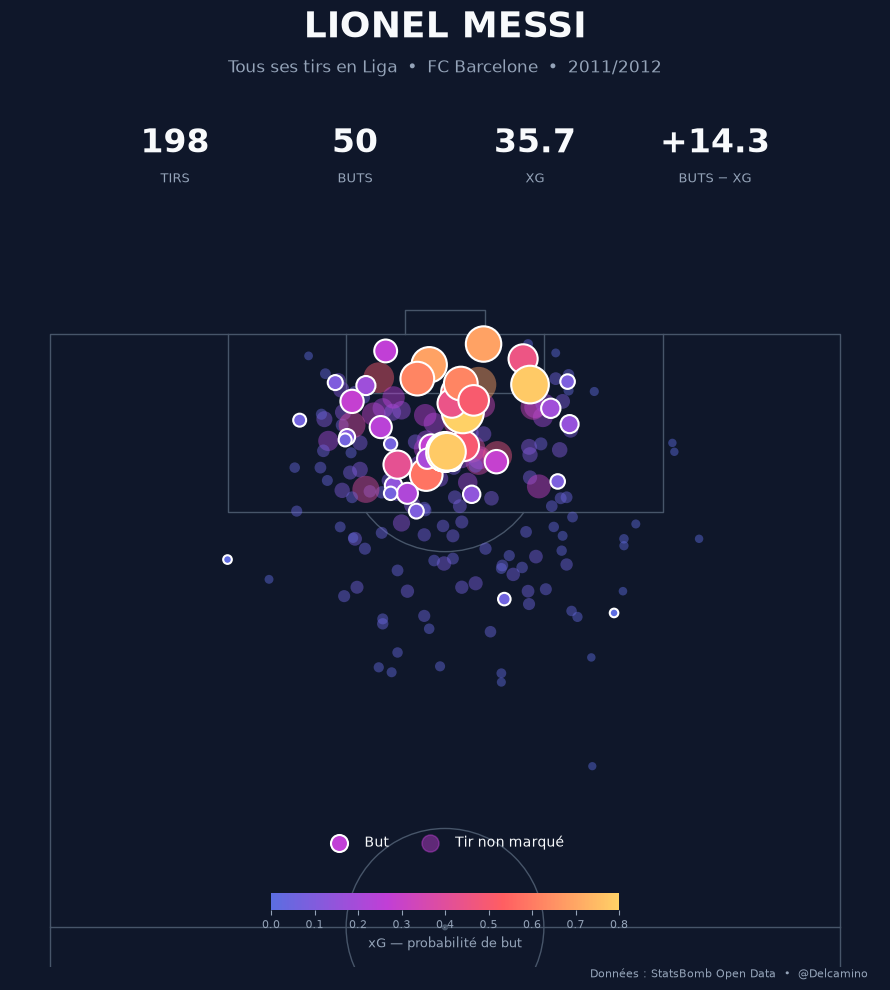

In [8]:
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable

# --- Palette ---
FOND    = "#0f172a"   # bleu nuit
LIGNES  = "#475569"   # gris ardoise
TEXTE   = "#f8fafc"   # blanc cassé
TEXTE_2 = "#94a3b8"   # gris clair (textes secondaires)

cmap_xg = LinearSegmentedColormap.from_list(
    "xg", ["#5b6ee1", "#c13fd6", "#ff5e62", "#ffd166"])
norm_xg = Normalize(vmin=0, vmax=0.8)

# --- Terrain ---
pitch = VerticalPitch(pitch_type="statsbomb", half=True,
                      pitch_color=FOND, line_color=LIGNES, linewidth=1,
                      goal_type="box", pad_top=32)
fig, ax = pitch.draw(figsize=(9, 10))
fig.set_facecolor(FOND)

# --- Tirs ratés : transparents ---
pitch.scatter(rates["x"], rates["y"], s=taille(rates["shot_statsbomb_xg"]),
              c=rates["shot_statsbomb_xg"], cmap=cmap_xg, norm=norm_xg,
              alpha=0.45, edgecolors="none", ax=ax, zorder=2)

# --- Buts : opaques + contour blanc ---
pitch.scatter(buts["x"], buts["y"], s=taille(buts["shot_statsbomb_xg"]),
              c=buts["shot_statsbomb_xg"], cmap=cmap_xg, norm=norm_xg,
              edgecolors="white", linewidth=1.5, ax=ax, zorder=3)

# --- En-tête ---
fig.text(0.5, 0.955, "LIONEL MESSI", ha="center",
         fontsize=26, fontweight="bold", color=TEXTE)
fig.text(0.5, 0.92, "Tous ses tirs en Liga  •  FC Barcelone  •  2011/2012",
         ha="center", fontsize=12, color=TEXTE_2)

# --- Tuiles de chiffres clés ---
tuiles = [("Tirs", f"{nb_tirs}"),
          ("Buts", f"{nb_buts}"),
          ("xG", f"{xg_total:.1f}"),
          ("Buts − xG", f"{ecart:+.1f}")]

for i, (label, valeur) in enumerate(tuiles):
    x = 0.2 + i * 0.2
    fig.text(x, 0.84, valeur, ha="center", fontsize=24, fontweight="bold", color=TEXTE)
    fig.text(x, 0.81, label.upper(), ha="center", fontsize=9, color=TEXTE_2)

# --- Légende but / raté ---
ax.scatter([], [], s=150, color="#c13fd6", edgecolors="white", linewidth=1.5, label="But")
ax.scatter([], [], s=150, color="#c13fd6", alpha=0.45, label="Tir non marqué")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 0.11), ncol=2,
          frameon=False, labelcolor=TEXTE, fontsize=10)

# --- Barre de couleur xG ---
cax = ax.inset_axes([0.3, 0.06, 0.4, 0.018])
cb = fig.colorbar(ScalarMappable(norm=norm_xg, cmap=cmap_xg), cax=cax, orientation="horizontal")
cb.set_label("xG — probabilité de but", color=TEXTE_2, fontsize=9)
cb.ax.tick_params(colors=TEXTE_2, labelsize=8)
cb.outline.set_visible(False)

# --- Source ---
fig.text(0.97, 0.015, "Données : StatsBomb Open Data  •  @Delcamino",
         ha="right", fontsize=8, color=TEXTE_2)

fig.savefig("../figures/messi_shotmap_2011_12_v2.png", dpi=300,
            bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()

### Let's visualize his shots density to observe where are his prefered shots areas. Take the same cell but change some code lines. 

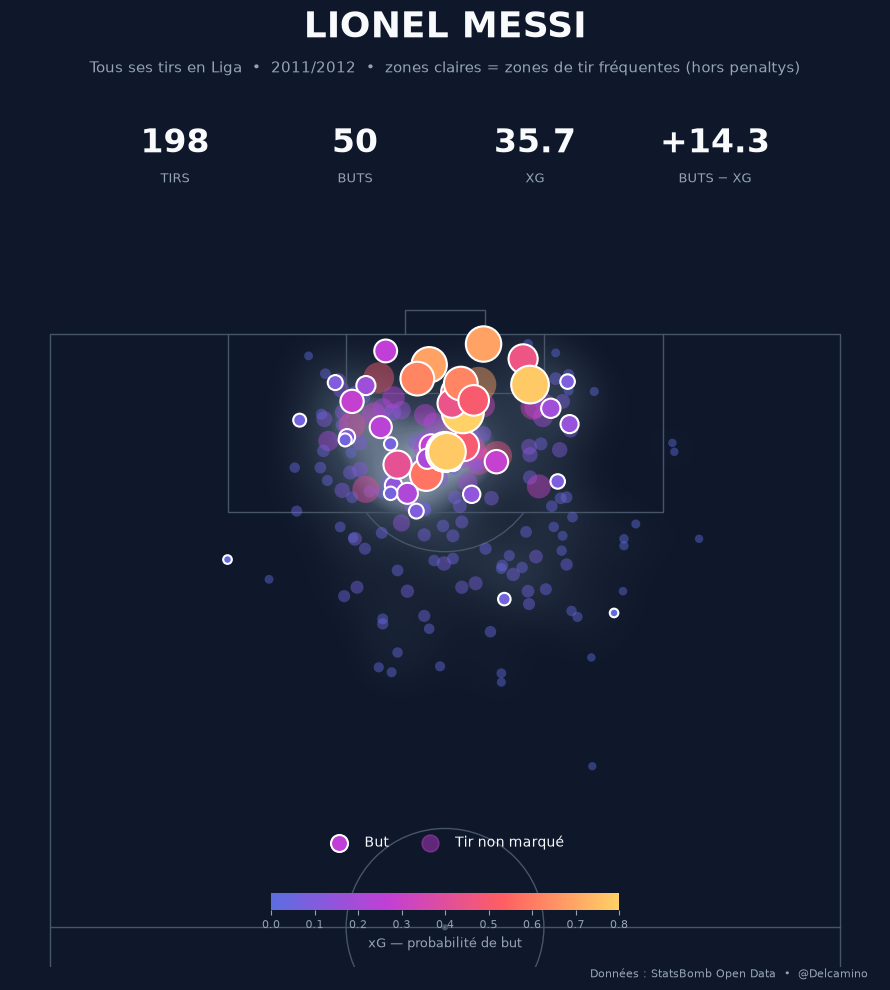

In [10]:
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable

# --- Palette ---
FOND    = "#0f172a"   # bleu nuit
LIGNES  = "#475569"   # gris ardoise
TEXTE   = "#f8fafc"   # blanc cassé
TEXTE_2 = "#94a3b8"   # gris clair (textes secondaires)

cmap_xg = LinearSegmentedColormap.from_list(
    "xg", ["#5b6ee1", "#c13fd6", "#ff5e62", "#ffd166"])
norm_xg = Normalize(vmin=0, vmax=0.8)

# --- Terrain ---
pitch = VerticalPitch(pitch_type="statsbomb", half=True,
                      pitch_color=FOND, line_color=LIGNES, linewidth=1,
                      goal_type="box", pad_top=32, line_zorder=2)
fig, ax = pitch.draw(figsize=(9, 10))
fig.set_facecolor(FOND)

# --- Carte de densité (hors penaltys) ---
tirs_jeu = tirs[tirs["shot_type"] != "Penalty"]

cmap_densite = LinearSegmentedColormap.from_list(
    "densite", [FOND, "#1e293b", "#334155", "#94a3b8"])

pitch.kdeplot(tirs_jeu["x"], tirs_jeu["y"], ax=ax,
              fill=True, levels=100, thresh=0.05, bw_adjust=0.8,
              cmap=cmap_densite, zorder=1)

# --- Tirs ratés : transparents ---
pitch.scatter(rates["x"], rates["y"], s=taille(rates["shot_statsbomb_xg"]),
              c=rates["shot_statsbomb_xg"], cmap=cmap_xg, norm=norm_xg,
              alpha=0.45, edgecolors="none", ax=ax, zorder=3)

# --- Buts : opaques + contour blanc ---
pitch.scatter(buts["x"], buts["y"], s=taille(buts["shot_statsbomb_xg"]),
              c=buts["shot_statsbomb_xg"], cmap=cmap_xg, norm=norm_xg,
              edgecolors="white", linewidth=1.5, ax=ax, zorder=4)

# --- En-tête ---
fig.text(0.5, 0.955, "LIONEL MESSI", ha="center",
         fontsize=26, fontweight="bold", color=TEXTE)
fig.text(0.5, 0.92, "Tous ses tirs en Liga  •  2011/2012  •  zones claires = zones de tir fréquentes (hors penaltys)",
         ha="center", fontsize=11, color=TEXTE_2)

# --- Tuiles de chiffres clés ---
tuiles = [("Tirs", f"{nb_tirs}"),
          ("Buts", f"{nb_buts}"),
          ("xG", f"{xg_total:.1f}"),
          ("Buts − xG", f"{ecart:+.1f}")]

for i, (label, valeur) in enumerate(tuiles):
    x = 0.2 + i * 0.2
    fig.text(x, 0.84, valeur, ha="center", fontsize=24, fontweight="bold", color=TEXTE)
    fig.text(x, 0.81, label.upper(), ha="center", fontsize=9, color=TEXTE_2)

# --- Légende but / raté ---
ax.scatter([], [], s=150, color="#c13fd6", edgecolors="white", linewidth=1.5, label="But")
ax.scatter([], [], s=150, color="#c13fd6", alpha=0.45, label="Tir non marqué")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 0.11), ncol=2,
          frameon=False, labelcolor=TEXTE, fontsize=10)

# --- Barre de couleur xG ---
cax = ax.inset_axes([0.3, 0.06, 0.4, 0.018])
cb = fig.colorbar(ScalarMappable(norm=norm_xg, cmap=cmap_xg), cax=cax, orientation="horizontal")
cb.set_label("xG — probabilité de but", color=TEXTE_2, fontsize=9)
cb.ax.tick_params(colors=TEXTE_2, labelsize=8)
cb.outline.set_visible(False)

# --- Source ---
fig.text(0.97, 0.015, "Données : StatsBomb Open Data  •  @Delcamino",
         ha="right", fontsize=8, color=TEXTE_2)

fig.savefig("../figures/messi_shotmap_2011_12_v2.png", dpi=300,
            bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()